<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
C:\Users\riley\AppData\Local\Temp\ipykernel_14980\3842543643.py:8: SyntaxWarning: invalid escape sequence '\s'
  csv_files = [base_path / "extragalactic_object_ids\sn_near_galaxy_candidate.csv"]



 Spot checking: sn_near_galaxy_candidate.csv (37 objects)
Plotting 170028526511063098...


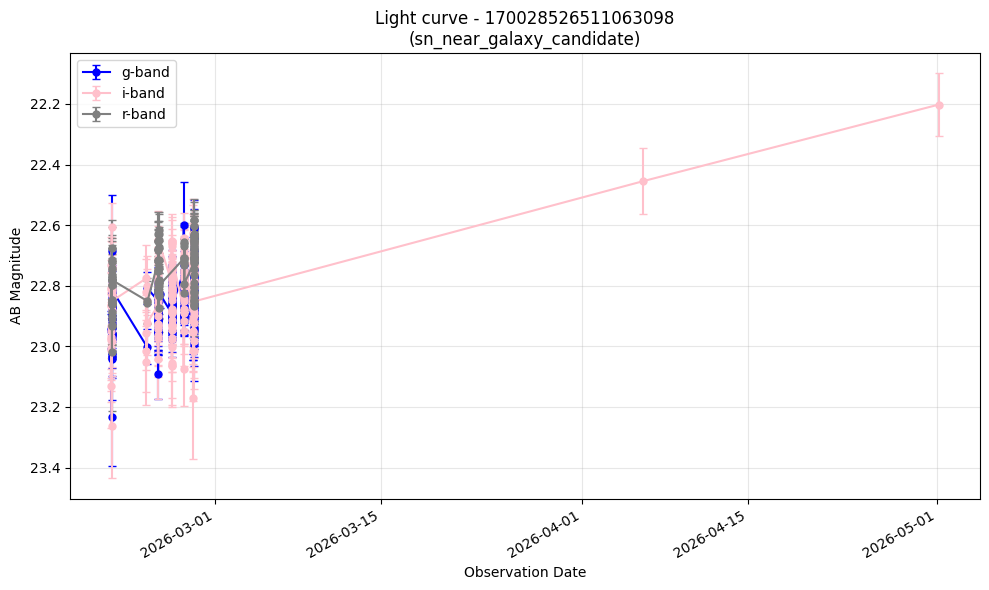

Plotting 170028526517354568...


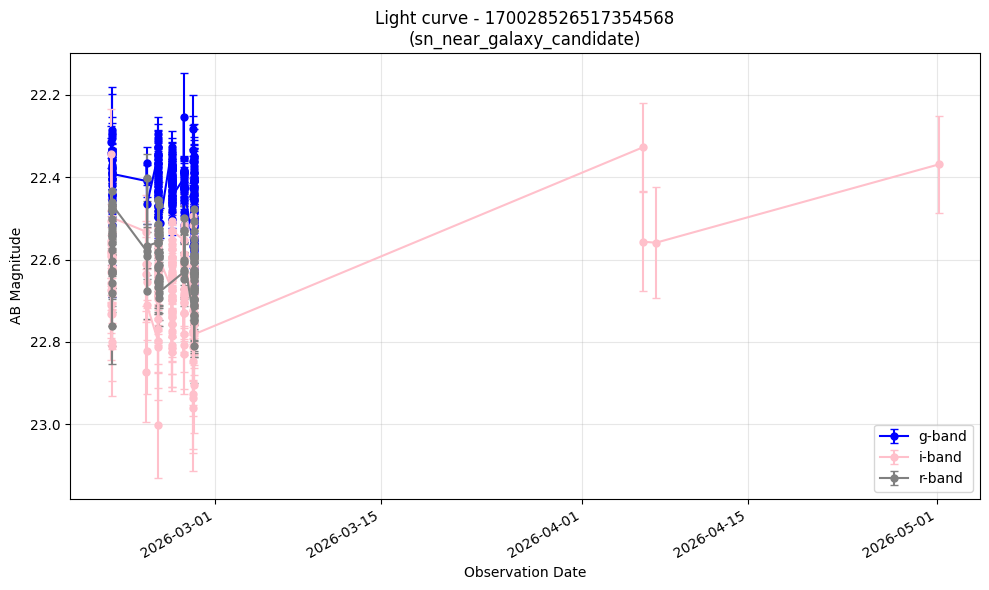

Plotting 170028526533608163...


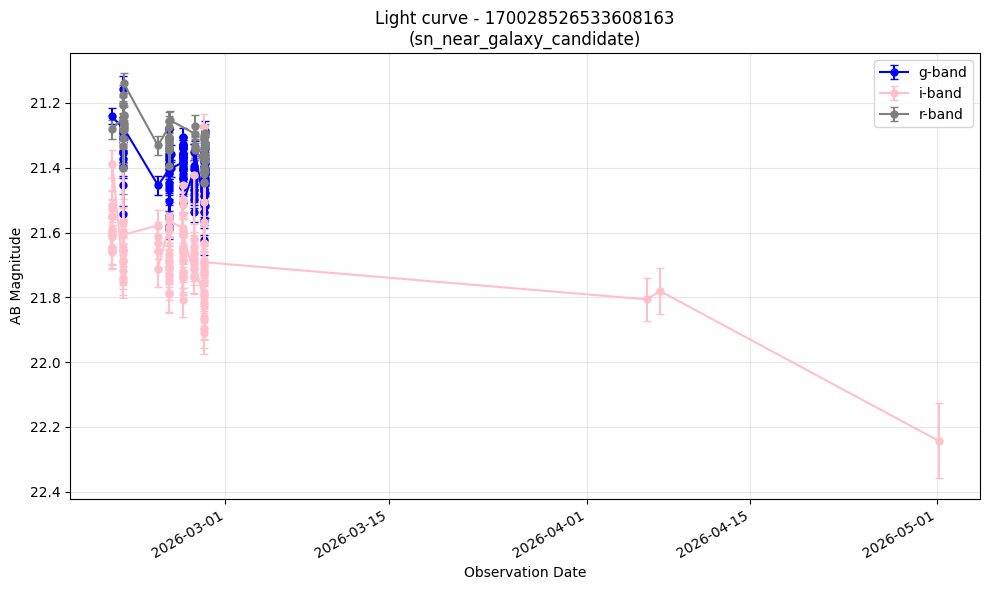

Plotting 170028526535180328...


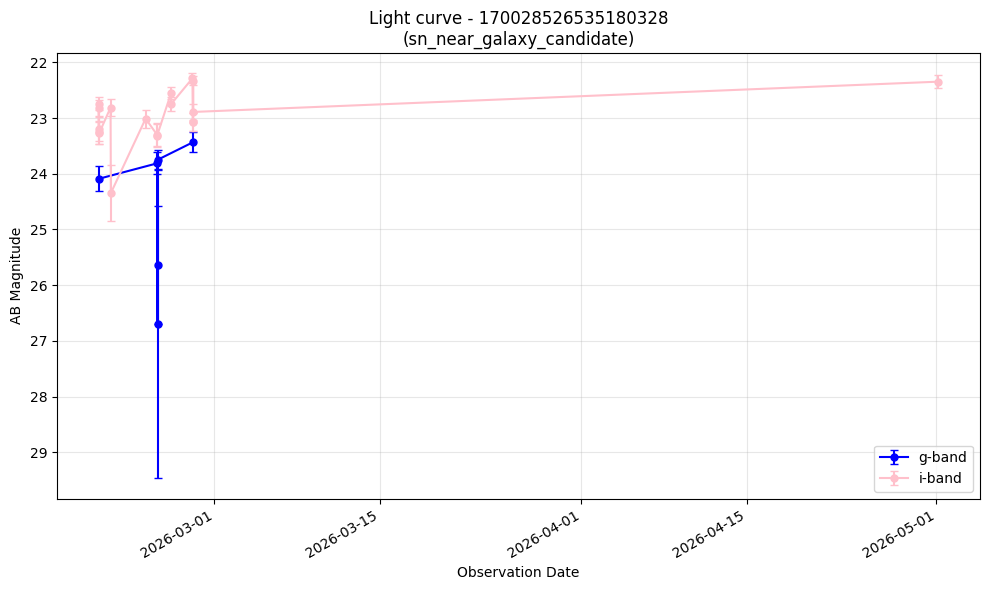

Plotting 170028526800994812...


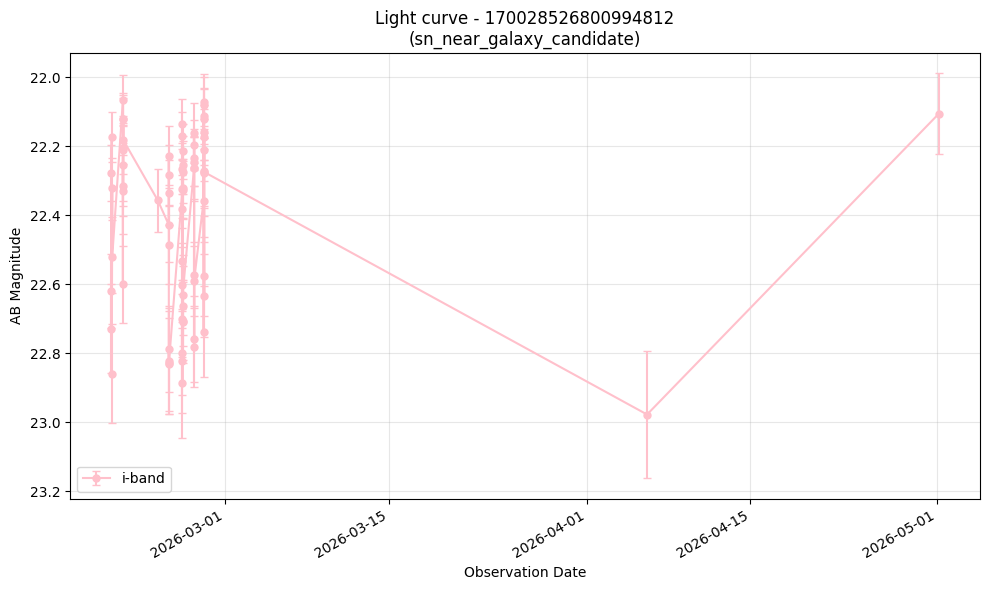

Plotting 170028534042984523...


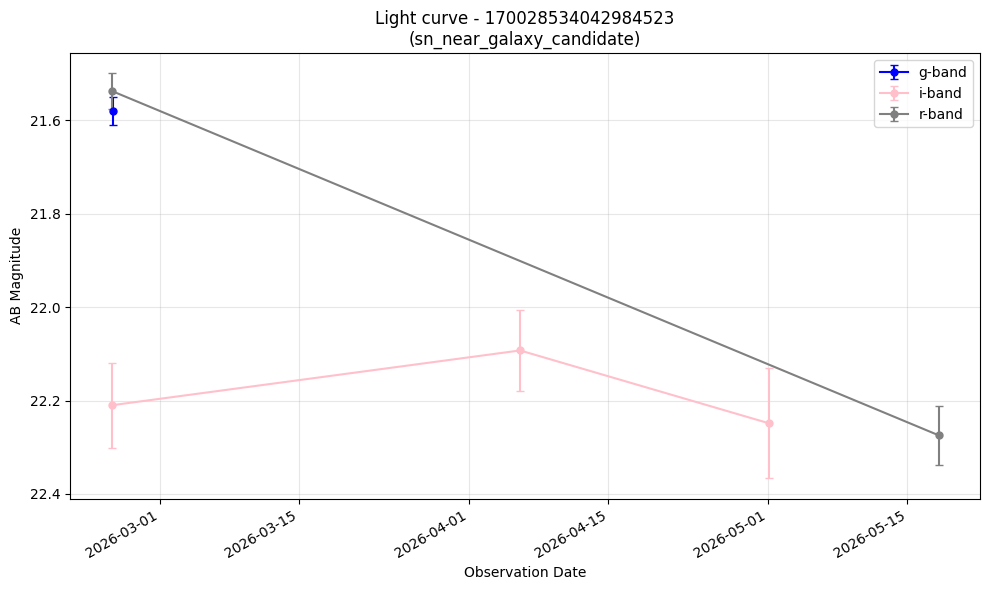

Plotting 313998569462300707...


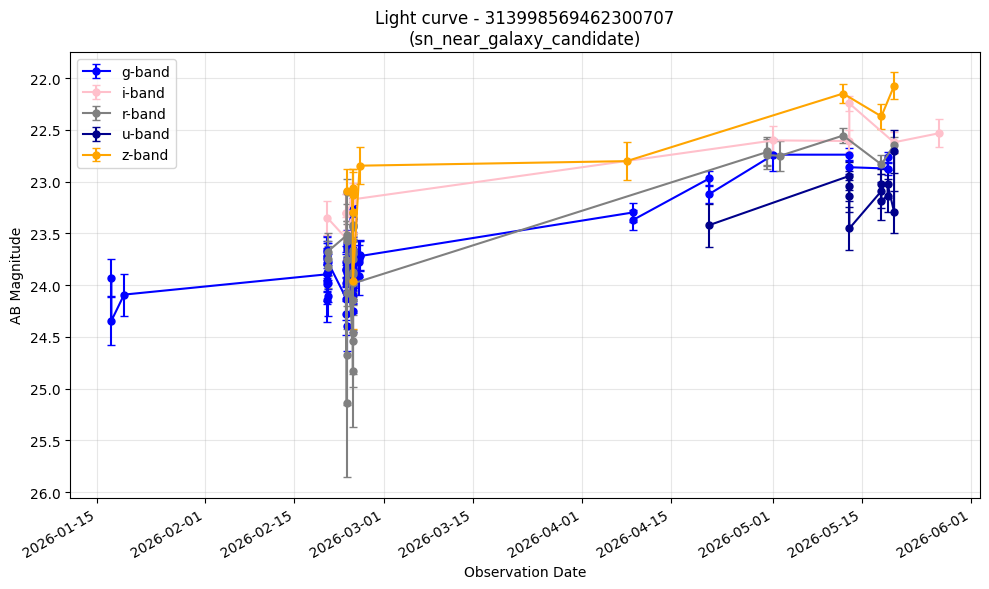

Plotting 313998569623257167...


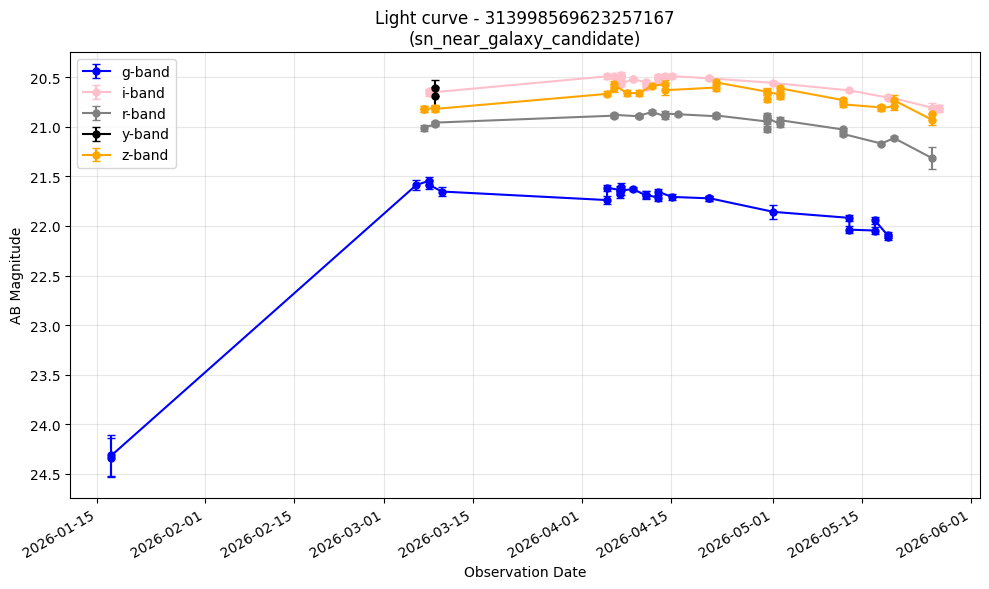

Plotting 314003013678137685...


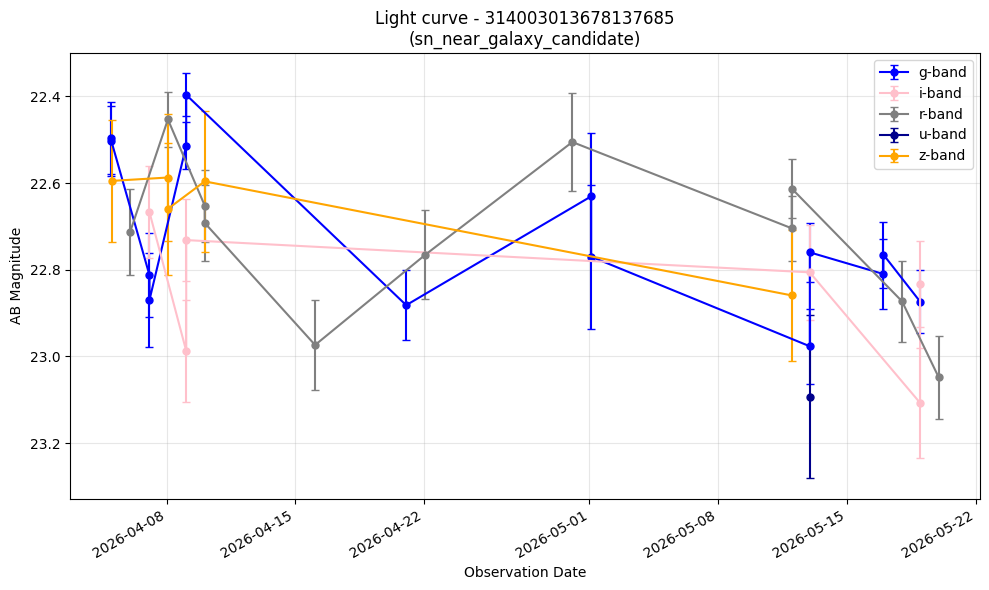

Plotting 314003014420004875...


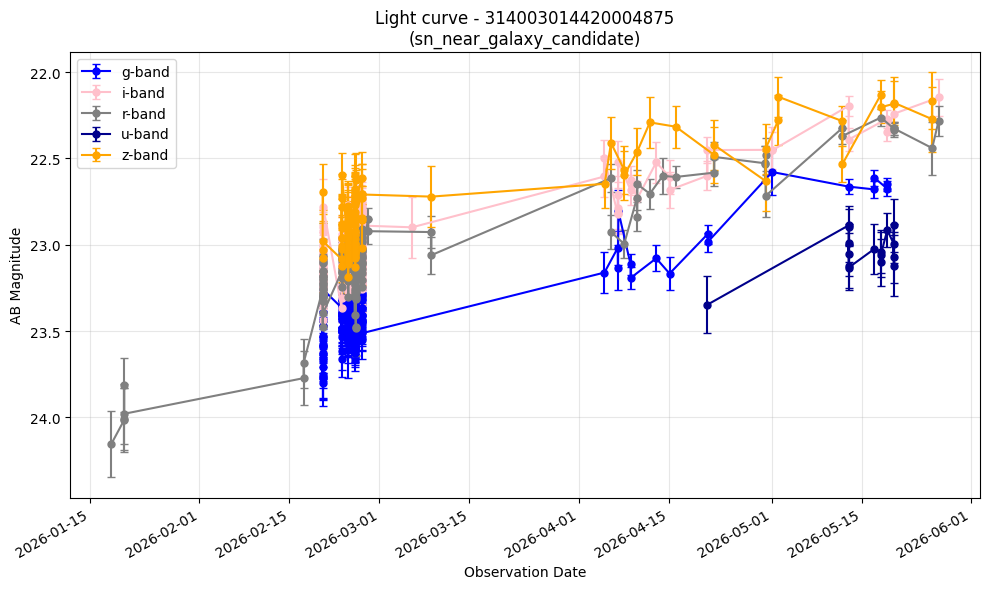

Plotting 313893021469376580...


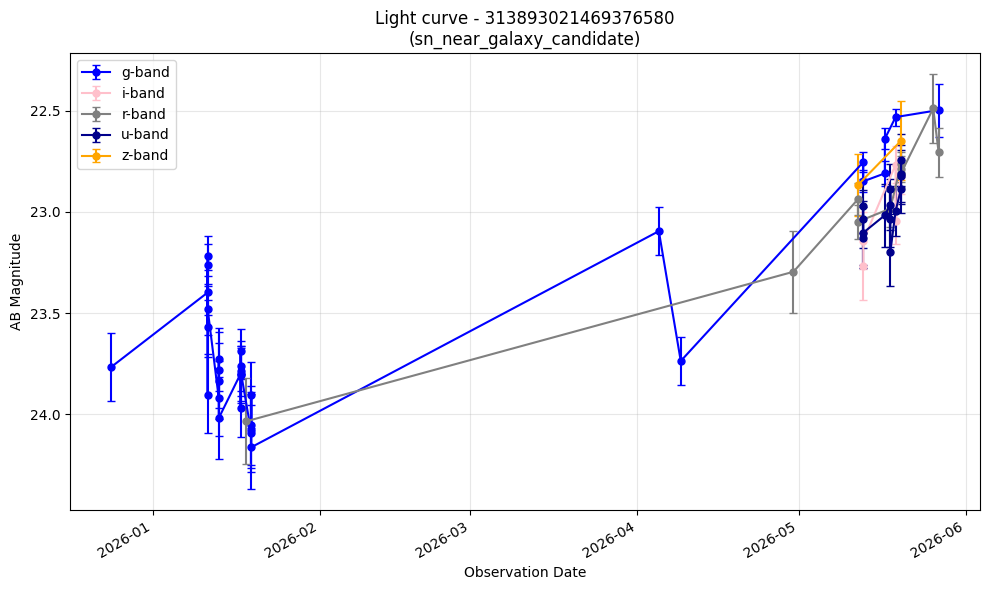

Plotting 313972182598287474...


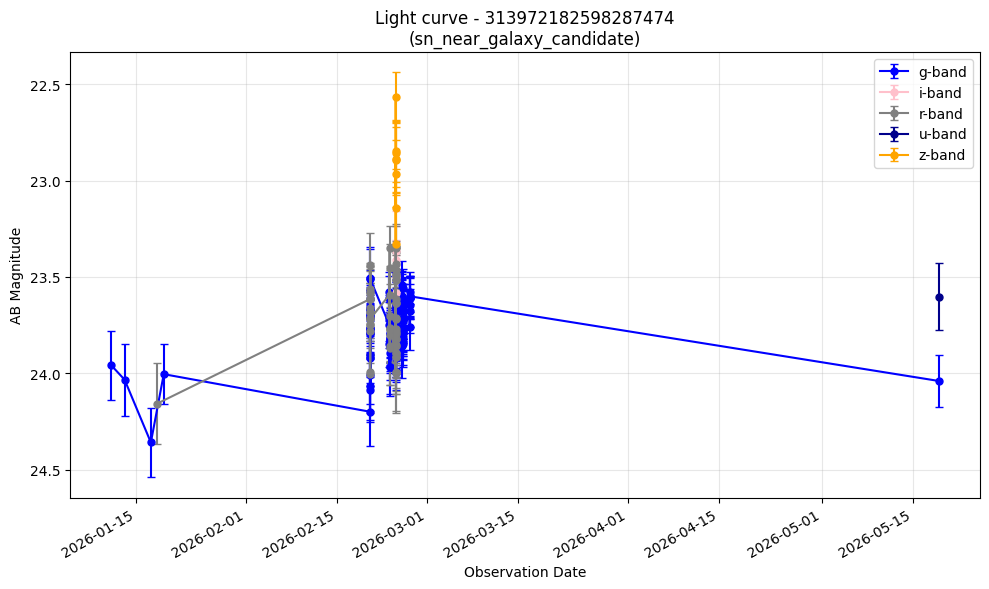

Plotting 313972182789128201...


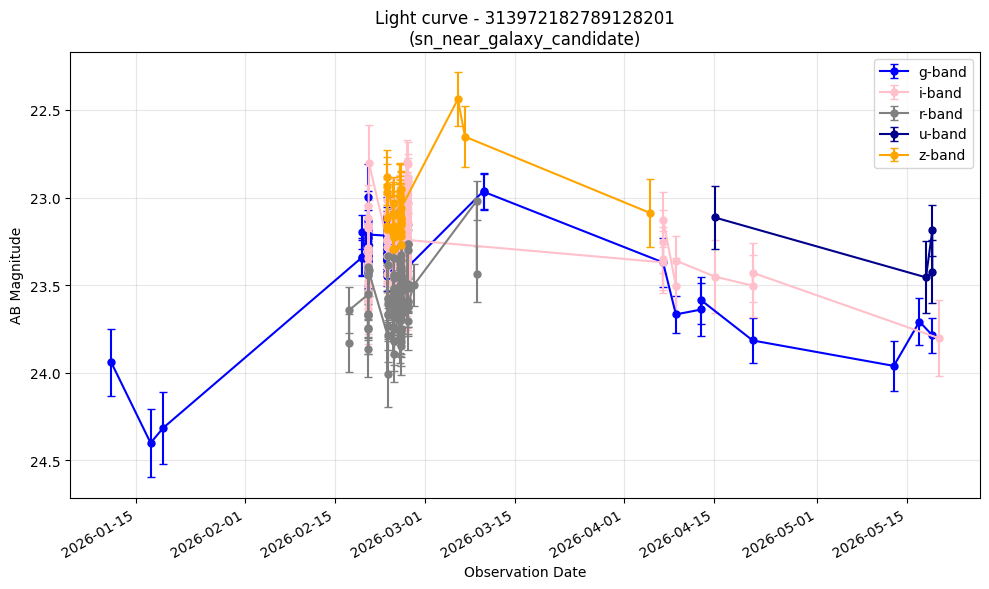

Plotting 313972183197024409...


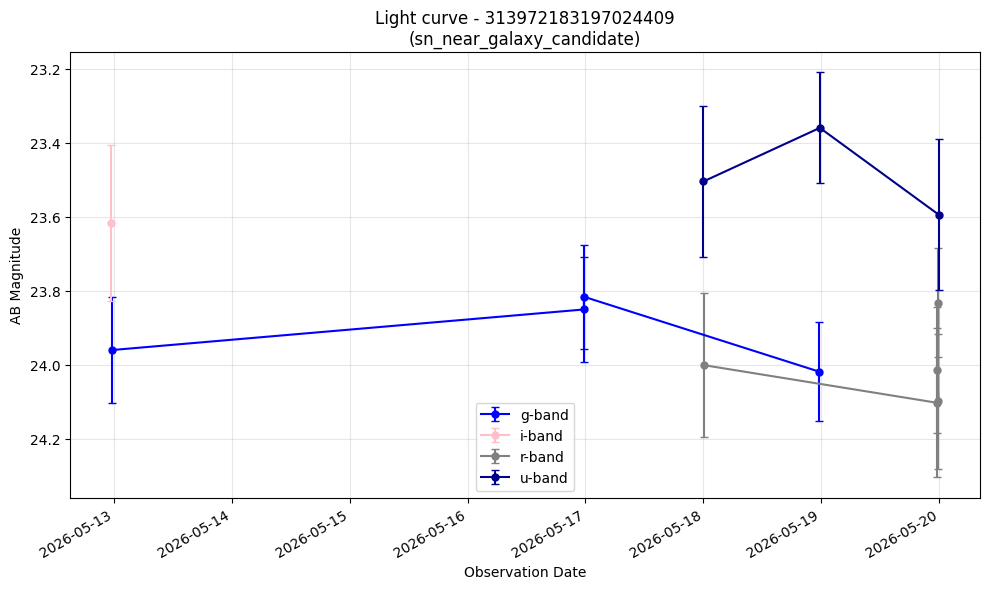

Plotting 313980947942342770...


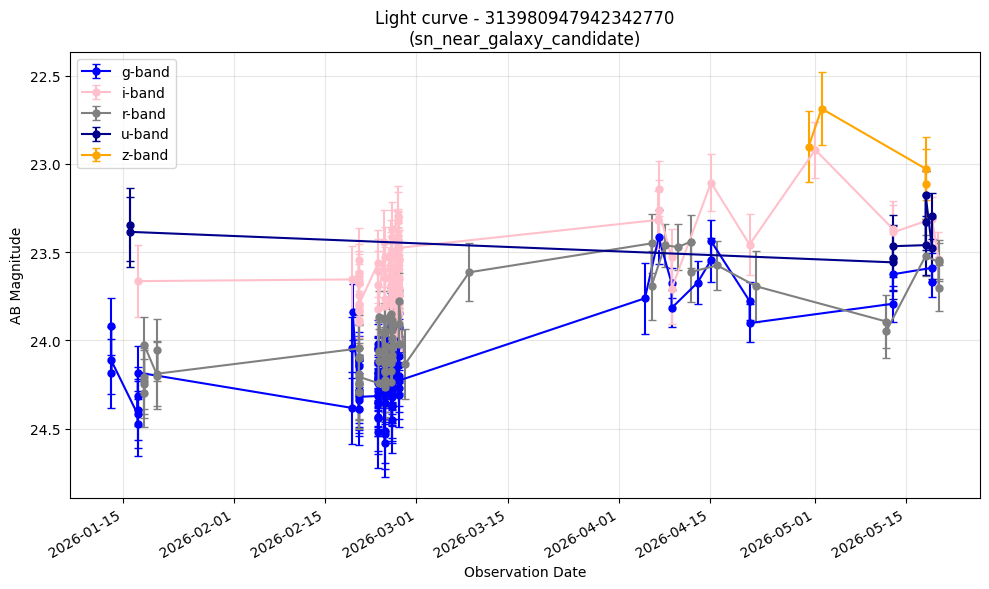

Plotting 313998535398260744...


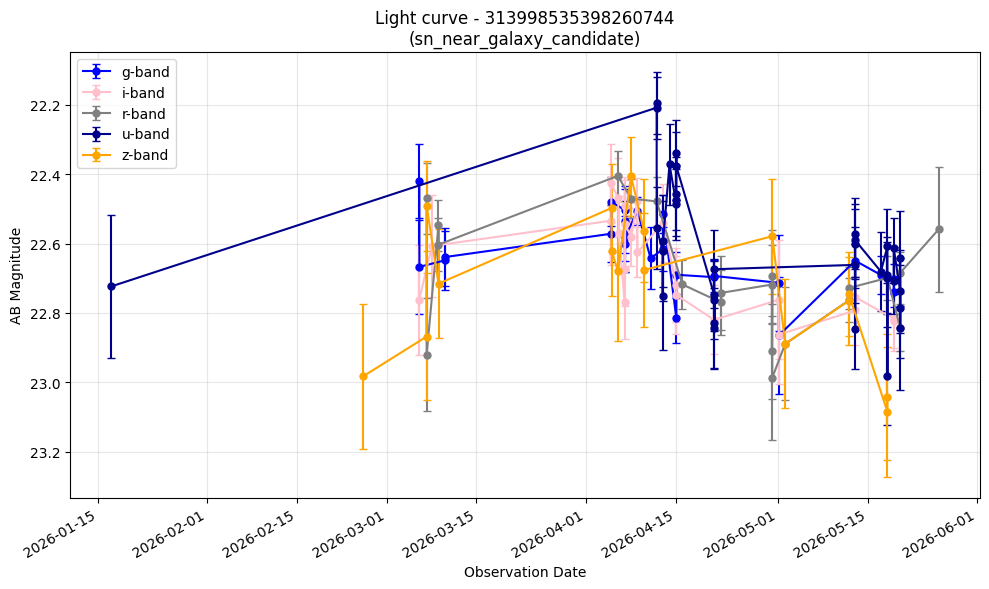

Plotting 313998569506865285...


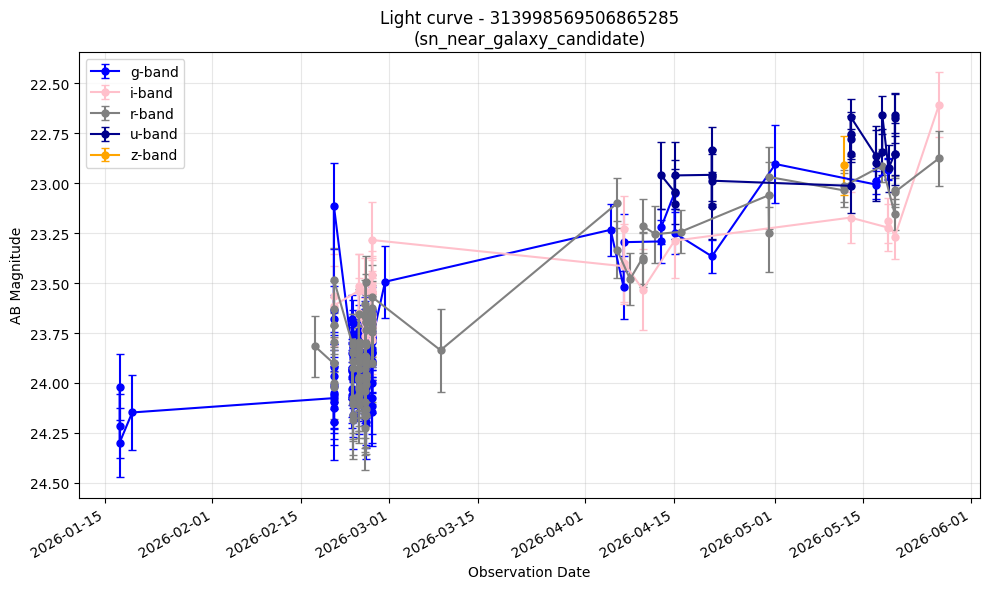

Plotting 313998569607004201...


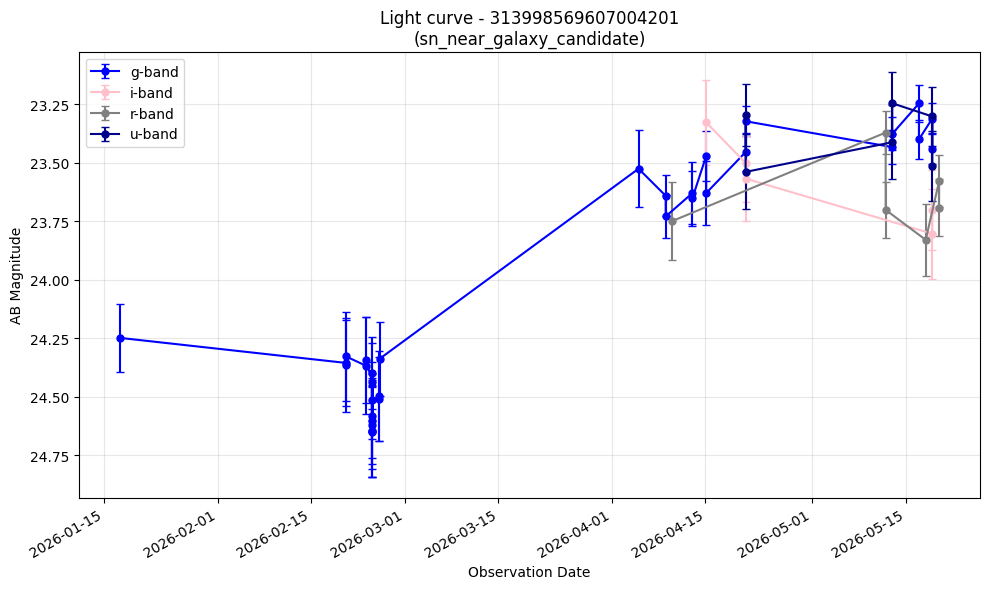

Plotting 313998570052124685...


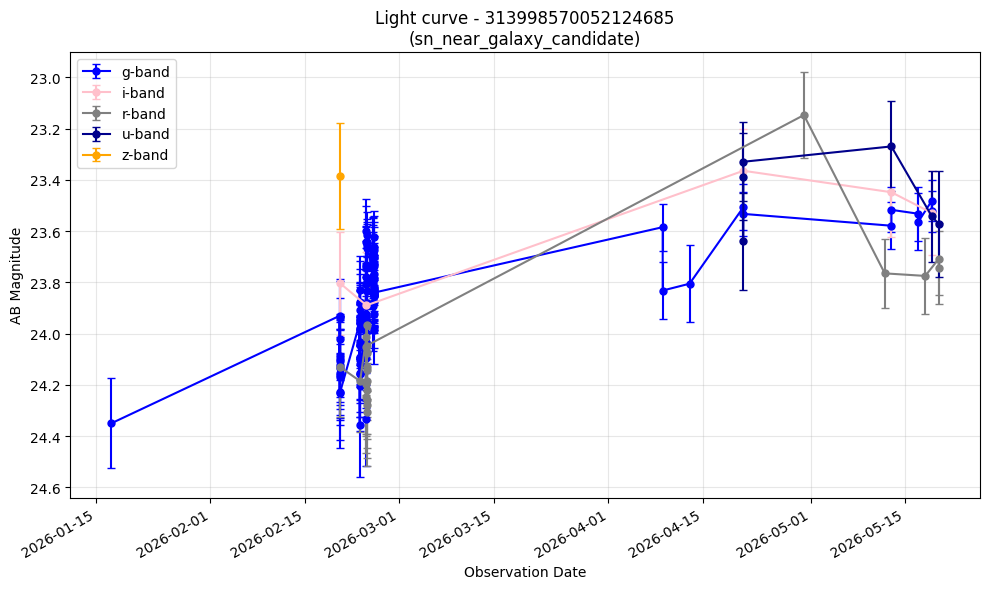

Plotting 170296772058939493...


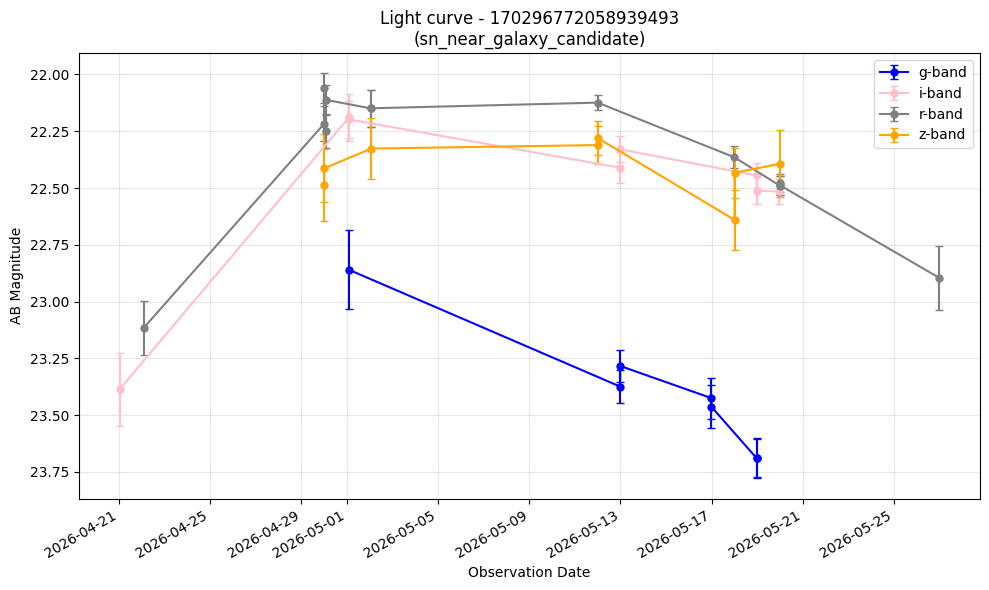

Plotting 170389126954614924...


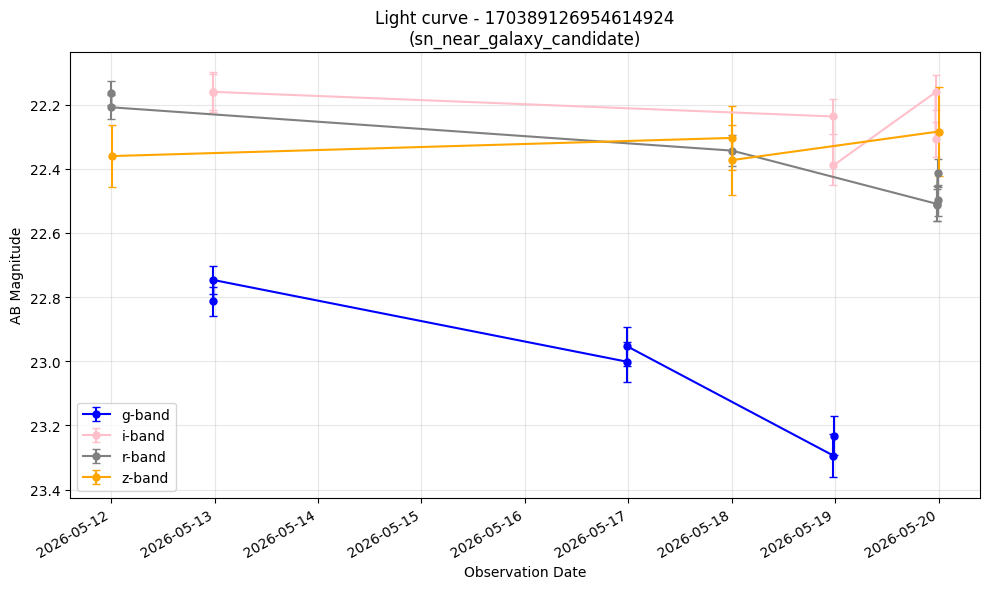

Plotting 313853517405093979...


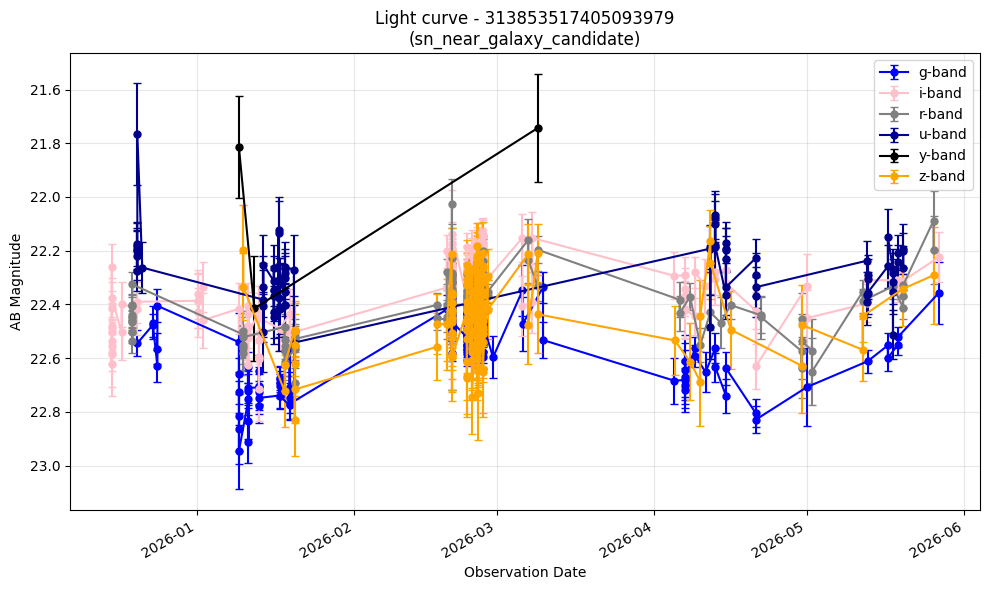

Plotting 313853517416628300...


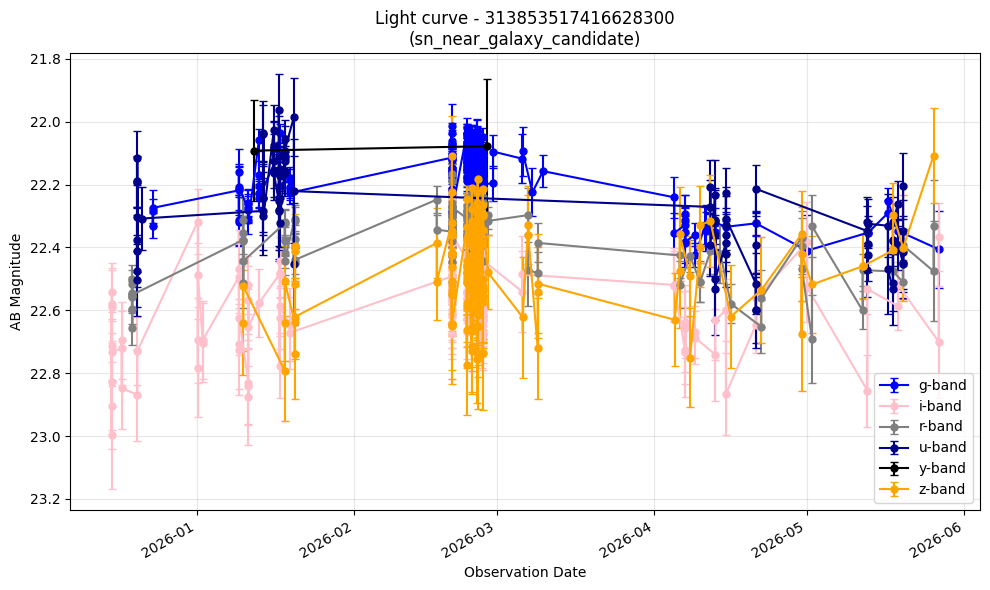

Plotting 313853533862494220...


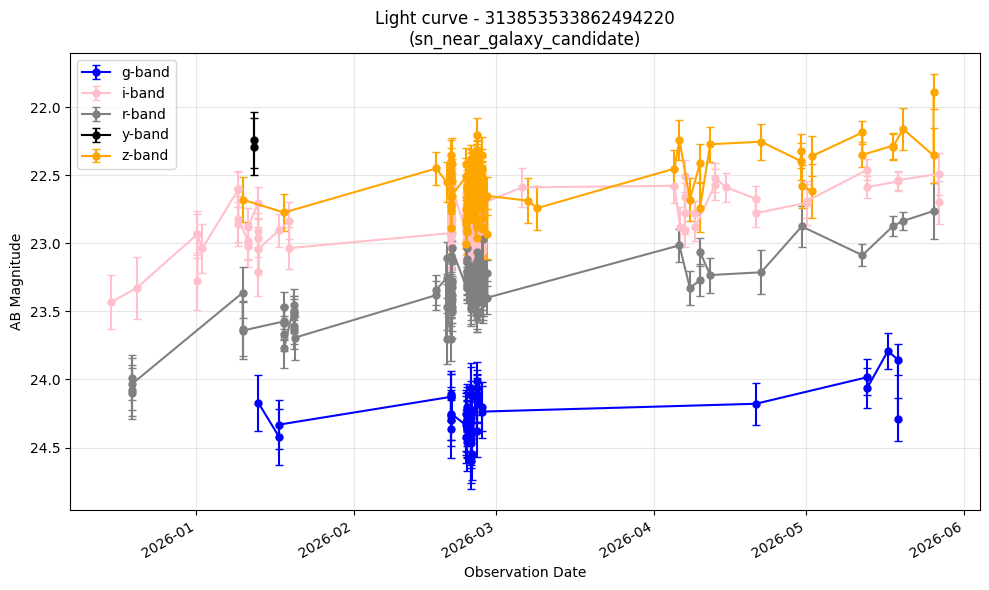

Plotting 313875416786927752...


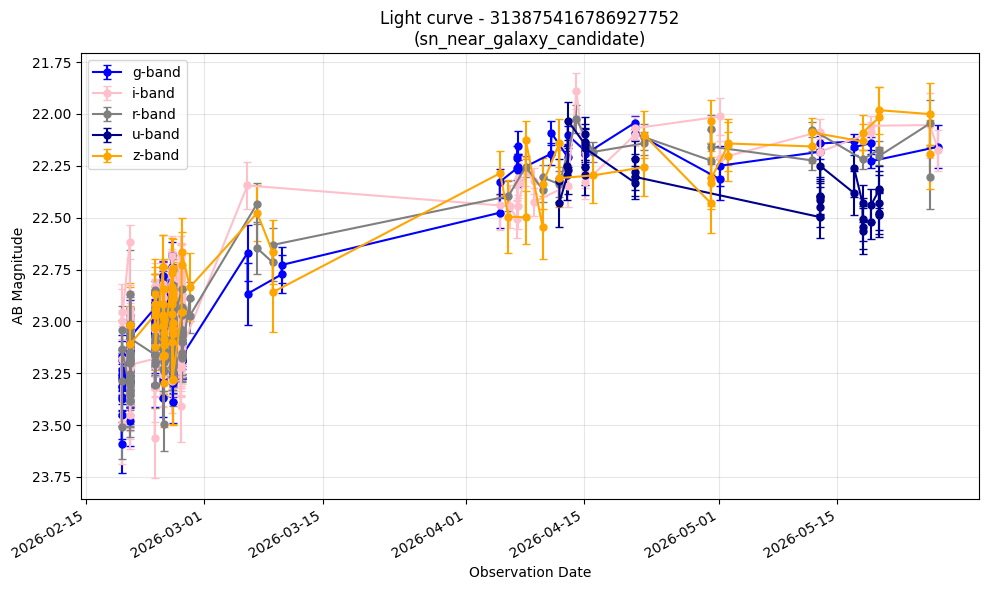

Plotting 313985345684242460...


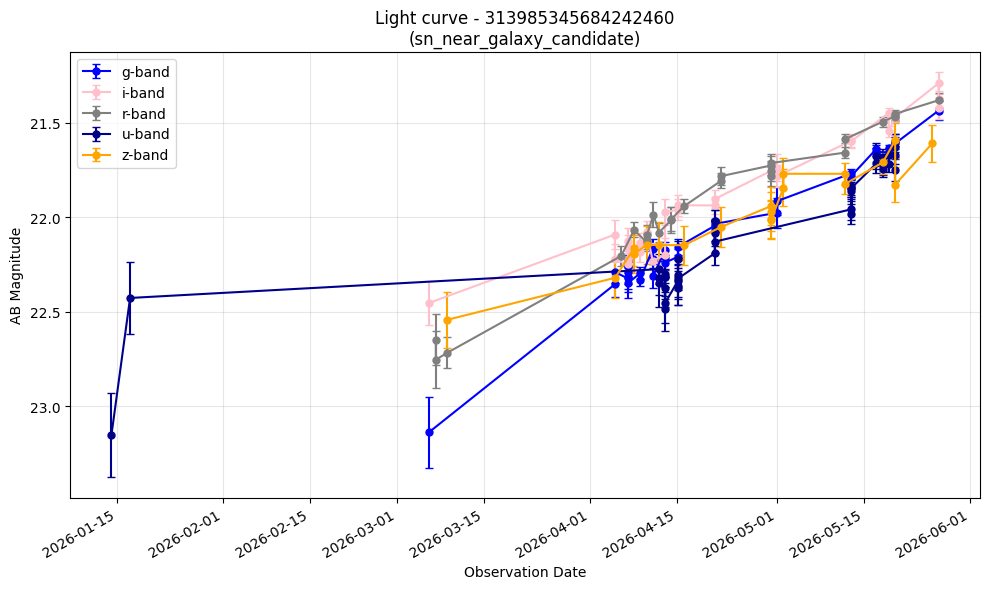

Plotting 170336356481892438...


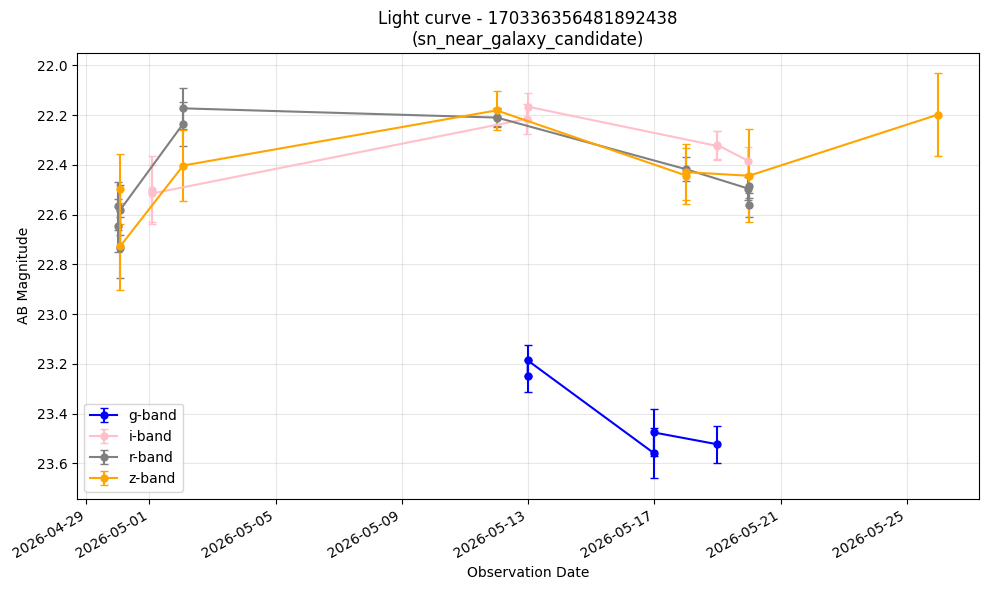

Plotting 313853517481115734...


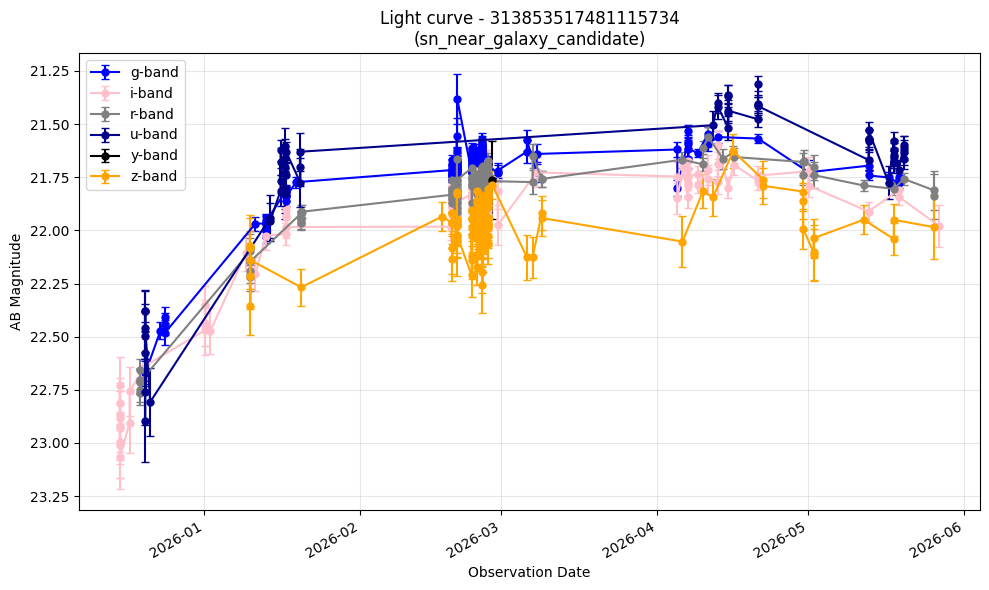

Plotting 313853517544554601...


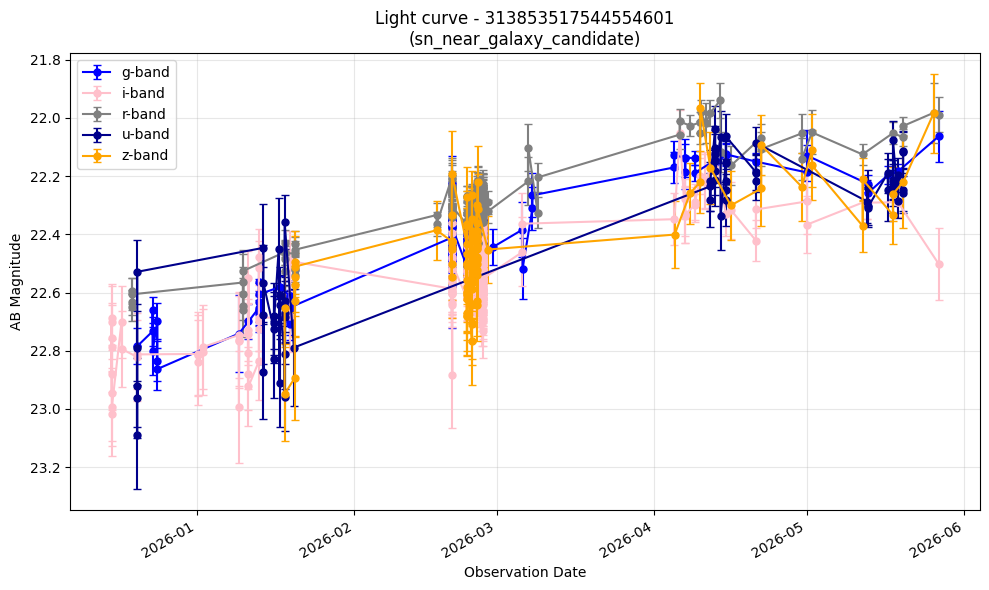

Plotting 313972184125538308...


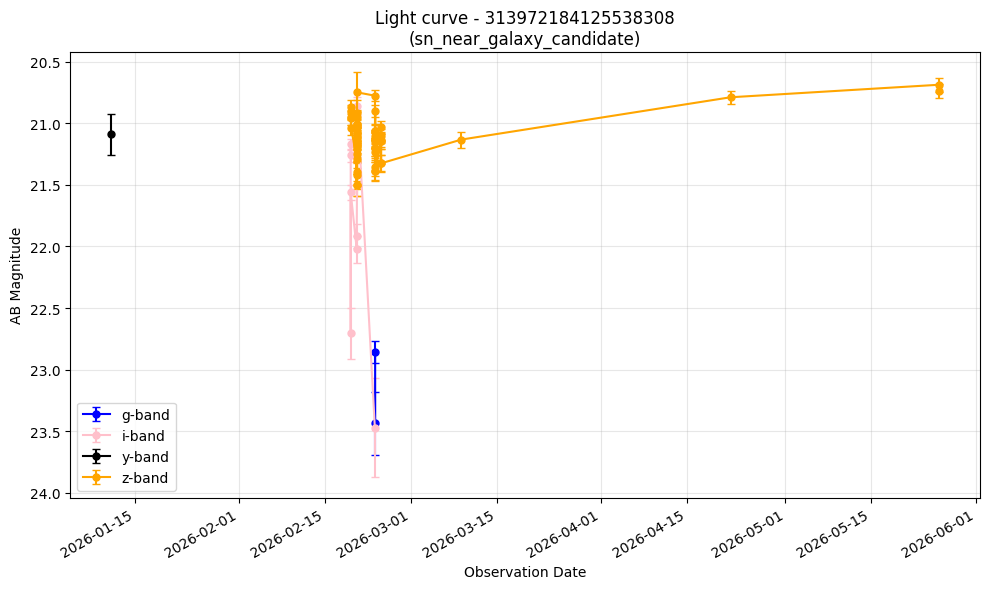

Plotting 314011776610992165...


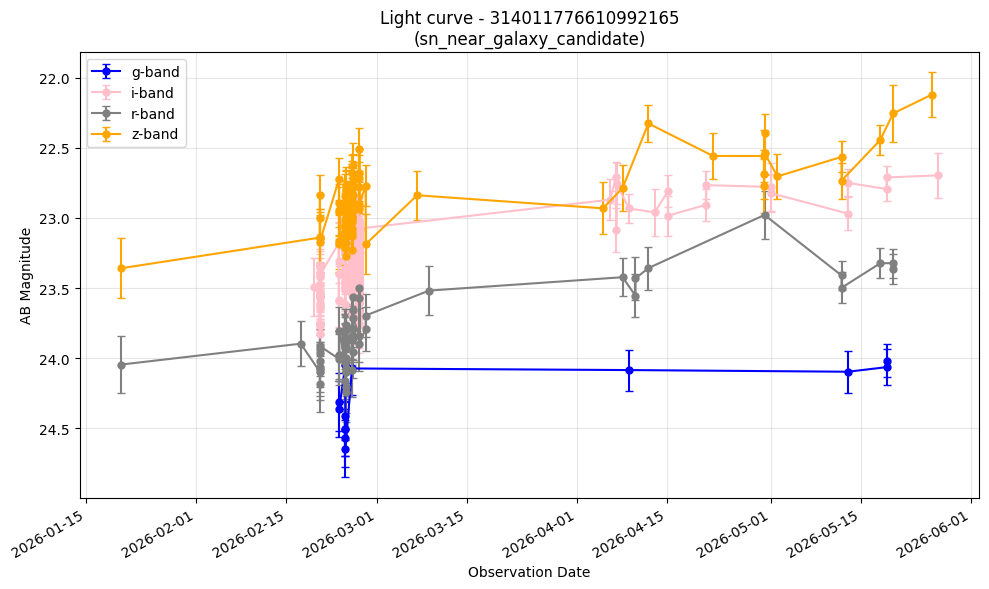

Plotting 313871013160419410...


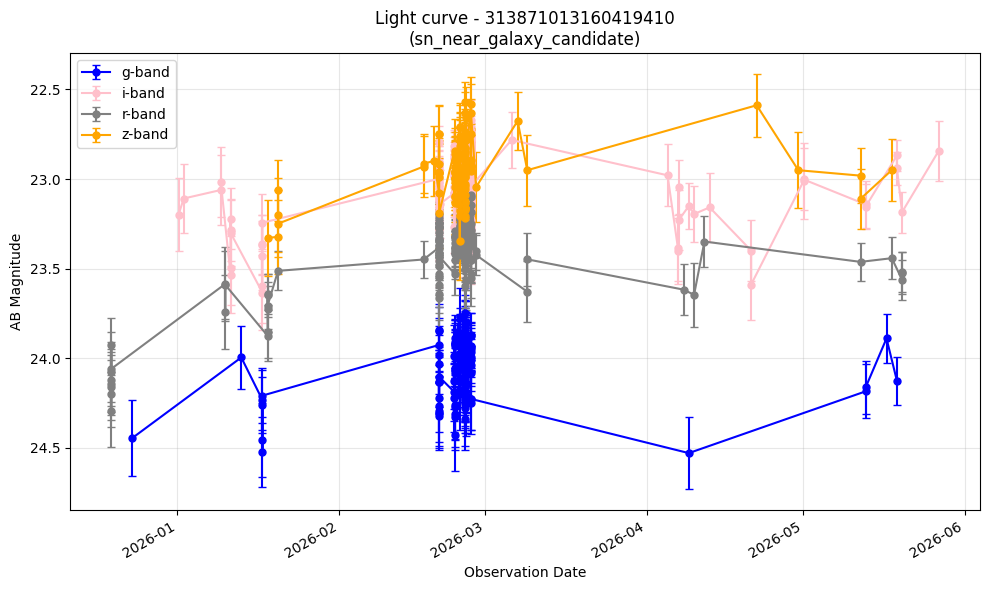

Plotting 313871013236965412...


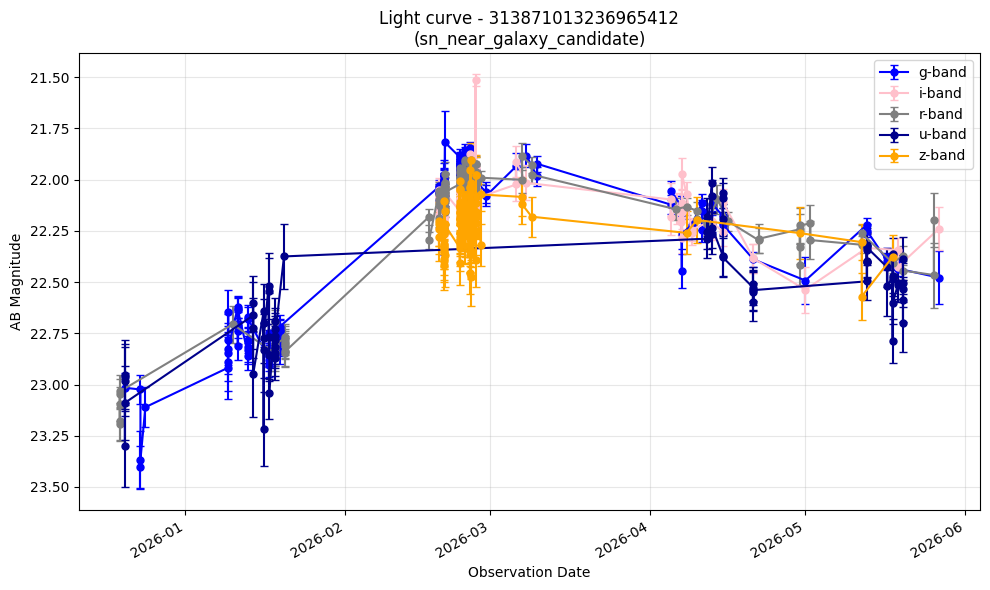

Plotting 313871014188548255...


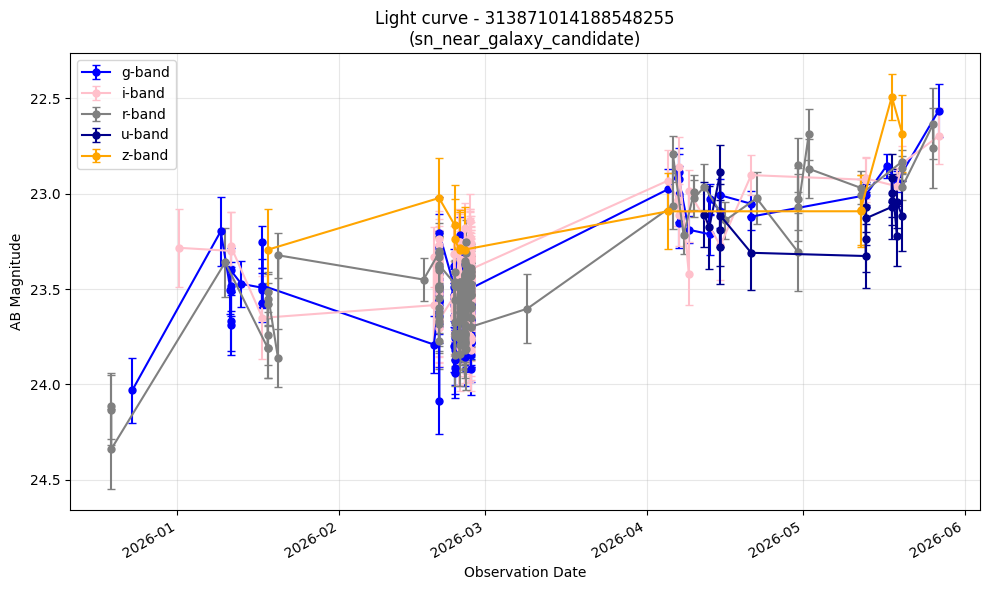

Plotting 313875415078273053...


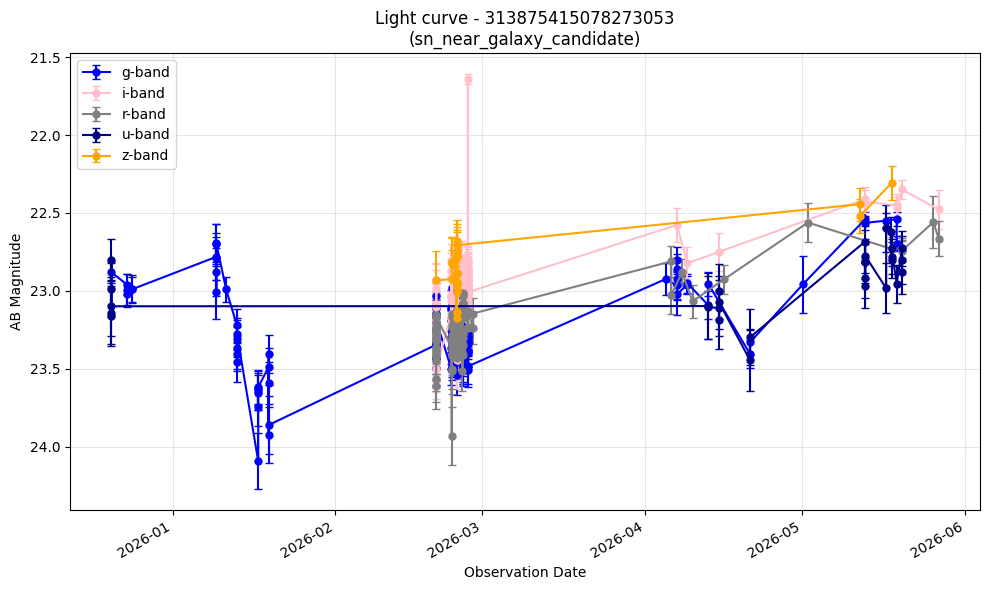

Plotting 313875416771199127...


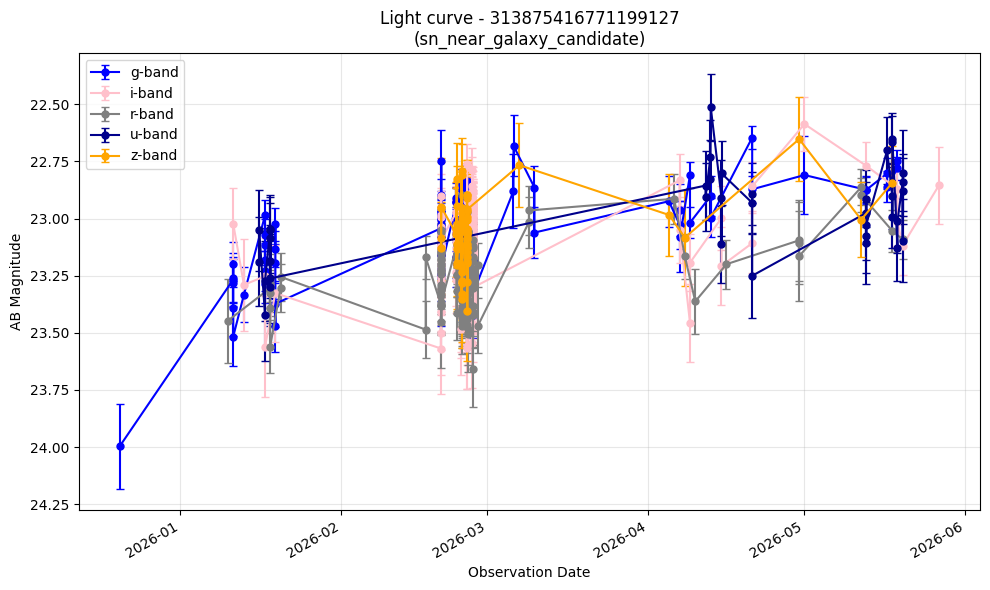

Plotting 313998534957858832...


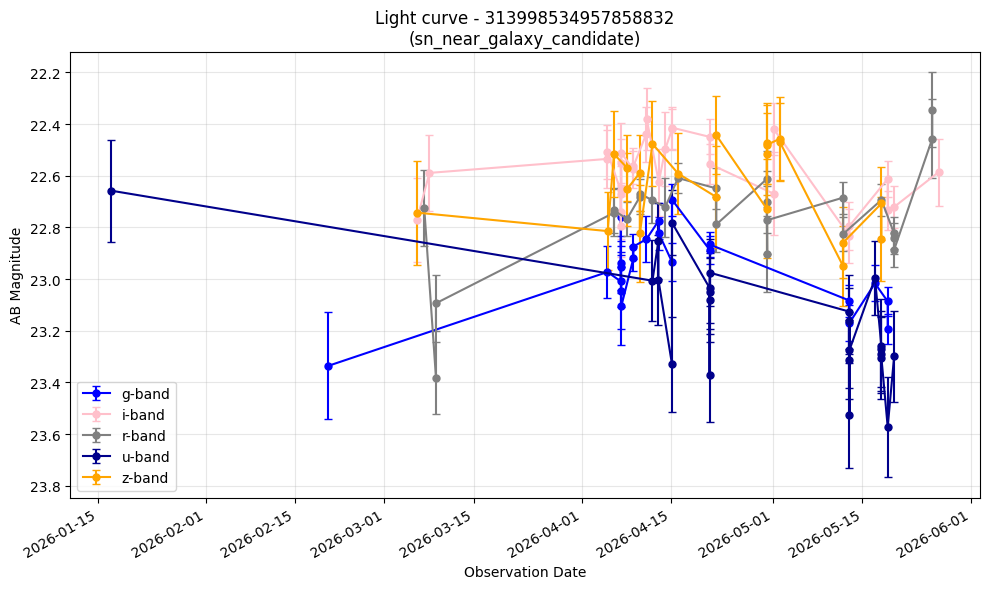

In [9]:
# reads and plots candidates that i need to spot check personally if they don't pass all three classifiers
from pathlib import Path
import pandas as pd
from light_curve_plotter import collect_light_curve_data, lightcurve_plotting

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data")

csv_files = [base_path / "extragalactic_object_ids\sn_near_galaxy_candidate.csv"]

for csv_file in csv_files:
    df_candidates = pd.read_csv(csv_file, dtype={"r:diaObjectId":str})  
    print (f"\n Spot checking: {csv_file.name} ({len(df_candidates)} objects)")
    for objectID in df_candidates["r:diaObjectId"]:
        print(f"Plotting {objectID}...")
        df_lc = collect_light_curve_data(objectID)
        if df_lc is not None:
            lightcurve_plotting(df_lc, objectID, csv_file.stem)

In [1]:
import requests as re
import pandas as pd
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
from pathlib import Path

# Using tags to filter through alerts, the tag is the string at [0] in each tuple with [1] being the path of the csv file being saved.
# sn_near_galaxy_candidate: Written by Anais Moller (Supervisor) - near galaxy extragalactic base with absolute magnitude cuts consistent with SNe.
# extragalactic_lt20mag_candidate: bright (mag < 20), rising extragalactic candidates - complementary to sn_near_galaxy as it has a rising component, doesn't have the abs mag cuts tho.
# in_tns: objects already reported to TNS - used as confirmed ground truth for pipeline validation.
# extragalactic_new_candidate removed: loose extragalactic flavor, no galaxy association, high contamination, single/double epoch objects only.
api_url_tags = "https://api.lsst.fink-portal.org/api/v1/tags"
base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\extragalactic_object_ids")
tags = [("sn_near_galaxy_candidate",        base_path / "sn_near_galaxy_candidate.csv"),
        ("extragalactic_lt20mag_candidate",  base_path / "extragalactic_lt20mag_candidate.csv"),
        ("in_tns",                           base_path / "candidates_in_TNS.csv")]

# Will run everyday and scan the last 24hrs of alerts.
# NOTE: Need to check what time Rubin is programmed to start the scan of the sky as I don't want to set the code going and miss when alerts are being sent out.
#startdate = (datetime.now(tz=ZoneInfo("Australia/Sydney")) - timedelta(days=1)).strftime("%Y-%m-%d")
#stopdate  = (datetime.now(tz=ZoneInfo("Australia/Sydney"))).strftime("%Y-%m-%d")

# Historical backfill dates - comment out the above and uncomment these for first run only.
startdate = "2025-10-25"
stopdate  = "2026-05-27"

N_ALERTS = 100000  # Keep at 100000 — increasing causes 504 timeouts. Completeness
                # is handled by splitting on ceiling hits in fetch_tag_with_fallback.
                # n parameter added and ceiling diagnosed with Claude Sonnet 4.6.

# fetch_tag_with_fallback was written by Claude Sonnet 4.6 with the prompt:
# "The 502 error is a one-time problem for the historical backfill. Add a minimal
# recursive date-splitting fallback that only activates on 502, leaving the daily
# pipeline logic unchanged."
# Updated by Claude Sonnet 4.6 to handle 504 Gateway Timeout with the prompt:
# "Increasing client timeout won't fix a 504. Add 504 to the recursive fallback."
# Updated by Claude Sonnet 4.6 to split on n ceiling hits with the prompt:
# "Still hitting alert ceiling at 6500 objects. Move ceiling check inside the
# fallback function and treat it like a server error — split and retry rather
# than increasing N_ALERTS which causes 504s."
def fetch_tag_with_fallback(tag: str, startdate: str, stopdate: str) -> list:
    """Fetch alerts for a tag between two dates.
    On 502/504, or if the n ceiling is hit, automatically splits the date range
    in half and retries each half to ensure completeness.
    For daily 24hr runs this will never trigger.
    """
    try:
        r = re.post(
            api_url_tags,
            json={
                "tag":           tag,
                "startdate":     startdate,
                "stopdate":      stopdate,
                "n":             N_ALERTS,
                "columns":       "r:diaObjectId",
                "output-format": "json",
            },
            timeout=120,
        )
        r.raise_for_status()
        raw = r.json()

        # If we hit the ceiling, the response is silently truncated — split to ensure
        # completeness rather than increasing N_ALERTS which causes 504 timeouts.
        if len(raw) >= N_ALERTS:
            raise _CeilingHit

        return raw

    except _CeilingHit:
        pass  # fall through to split logic below

    except re.exceptions.HTTPError as e:
        if e.response.status_code not in (502, 504):
            raise

    # --- split and retry ---
    start_dt = datetime.strptime(startdate, "%Y-%m-%d")
    stop_dt  = datetime.strptime(stopdate,  "%Y-%m-%d")
    mid_dt   = start_dt + (stop_dt - start_dt) / 2

    if mid_dt == start_dt or mid_dt == stop_dt:
        print(f"  Could not split further for {startdate} -> {stopdate}, skipping.")
        return []

    mid = mid_dt.strftime("%Y-%m-%d")
    print(f"  Splitting {startdate} -> {stopdate} at {mid}")
    left  = fetch_tag_with_fallback(tag, startdate, mid)
    right = fetch_tag_with_fallback(tag, mid, stopdate)
    return left + right


class _CeilingHit(Exception):
    """Raised internally when the API n ceiling is reached."""
    pass

def data_ingestion(startdate, stopdate):
    for tag, output_path in tags:
        print(f"\nIngesting tag: {tag}")

        raw_alerts = fetch_tag_with_fallback(tag, startdate, stopdate)
        print(f"Raw alerts returned: {len(raw_alerts)}")

        new_extragalactic_ids = sorted(set([str(val["r:diaObjectId"]) for val in raw_alerts]))
        df_new = pd.DataFrame({"r:diaObjectId": new_extragalactic_ids})

        if len(df_new) == 0:
            print(f"No new candidates for tag: {tag}")
            continue

        if output_path.exists():
            existing_df = pd.read_csv(output_path, dtype={"r:diaObjectId": str})
            combined_df = pd.concat([existing_df, df_new], ignore_index=True)
            combined_df = combined_df.drop_duplicates(subset="r:diaObjectId")
        else:
            combined_df = df_new

        combined_df.to_csv(output_path, index=False)
        print(f"The number of new candidates found is {len(df_new)}")
        print(f"The total number of candidates in the catalogue is {len(combined_df)}")

data_ingestion(startdate, stopdate)


Ingesting tag: sn_near_galaxy_candidate
  Splitting 2025-10-25 -> 2026-05-27 at 2026-02-09
  Splitting 2026-02-09 -> 2026-05-27 at 2026-04-03
  Splitting 2026-02-09 -> 2026-04-03 at 2026-03-07
  Splitting 2026-02-09 -> 2026-03-07 at 2026-02-22
  Splitting 2026-02-09 -> 2026-02-22 at 2026-02-15
  Splitting 2026-02-15 -> 2026-02-22 at 2026-02-18
  Splitting 2026-02-18 -> 2026-02-22 at 2026-02-20
  Splitting 2026-02-22 -> 2026-03-07 at 2026-02-28
  Splitting 2026-02-22 -> 2026-02-28 at 2026-02-25
  Splitting 2026-02-22 -> 2026-02-25 at 2026-02-23
  Splitting 2026-02-23 -> 2026-02-25 at 2026-02-24
  Splitting 2026-02-25 -> 2026-02-28 at 2026-02-26
Raw alerts returned: 331329
The number of new candidates found is 32165
The total number of candidates in the catalogue is 32187

Ingesting tag: extragalactic_lt20mag_candidate
Raw alerts returned: 1431
The number of new candidates found is 329
The total number of candidates in the catalogue is 329

Ingesting tag: in_tns
Raw alerts returned: 351